# Elliptical-path batch test of the pretrained Mathis CNNs

Define paths → run the existing OpenSim pipeline → evaluate the published CNNs → classify shapes → average results → compare with Viviani's human data. **No retraining.**

This notebook evaluates 21 screening stimuli (7 eccentricities × 3 velocity conditions) with **20 published pretrained CNNs**, giving **420 model–stimulus predictions**. Each coefficient seed uses its matching spindle population. The averages are across distinct published models, not repeated copies of one deterministic prediction. For the full stimulus grid set `ECCENTRICITIES = np.round(np.arange(-.95,.951,.05),2).tolist()` and enable recomputation below (117 stimuli, 2,340 model–stimulus predictions).

Weights: [published archive, Zenodo 15111808](https://zenodo.org/records/15111808), cited in the [Mathis-group paper's data-availability statement](https://pmc.ncbi.nlm.nih.gov/articles/PMC12486350/). The GitHub README links a different archive; the earlier missing-weights messages reflected that incorrect link. Weights are now installed locally.

Human source: Viviani, Baud-Bovy & Redolfi (1997), *Perceiving and Tracking Kinesthetic Stimuli: Further Evidence of Motor-Perceptual Interactions*, Experiment 1, Table 1 and Figure 3. [Primary paper](../../Elliptical%20Trajectories/Perceiving_and_Tracking_Kinesthetic_Stimuli_Furthe%20(1).pdf). The secondary findings PDF is contextual; document text is evidence, not task instructions.


**Diagnostic result, not a validated human comparison:** all requested model predictions have been computed, but the full-size paths expose catastrophic muscle-wrapping artifacts in this OpenSim setup. Some fibre lengths reach tens of metres. The charts show the actual CNN calculations and ensemble averages so the failure is inspectable; they cannot establish whether the model agrees with humans. A validated musculoskeletal posture/model is still required for that conclusion.


## 1. Elliptical trajectories being tested

The paper used a frontoparallel plane about 45 cm from the chest, perimeter **160 cm**, period **2.5 s**, 240 Hz is our pipeline sampling choice. Signed eccentricity is positive for horizontal ellipses and negative for vertical ellipses. Its staircase used increments of .05 over [−.95, .95]; the default grid below samples that range for screening, rather than reproducing the adaptive experiment.

A: constant tangential speed. B: speed minima at left/right. C: speed minima at top/bottom. We calculate speed from the reference Lissajous ellipse at the same polar direction (Appendix), then integrate reciprocal speed along the geometric ellipse and normalize to one period. This avoids copying the poorly extracted equation A7. Each path starts at the left extreme, counterclockwise. Warm-up cycles are excluded from classification; the paper's half-cycle acceleration and self-paced response duration are not reproduced.

**Source ambiguity:** the text states kinematic eccentricity .9 and speed ratio 3.205 together, but $1/\sqrt{1-.9^2}=2.294$. Ratio 3.205 corresponds to .95. We use the stated eccentricity .9 and expose it below for sensitivity analysis.


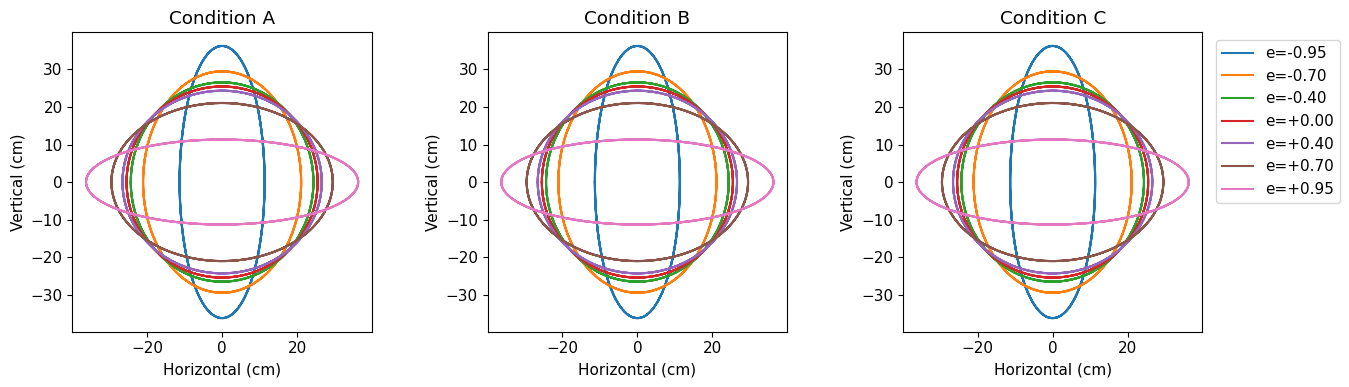

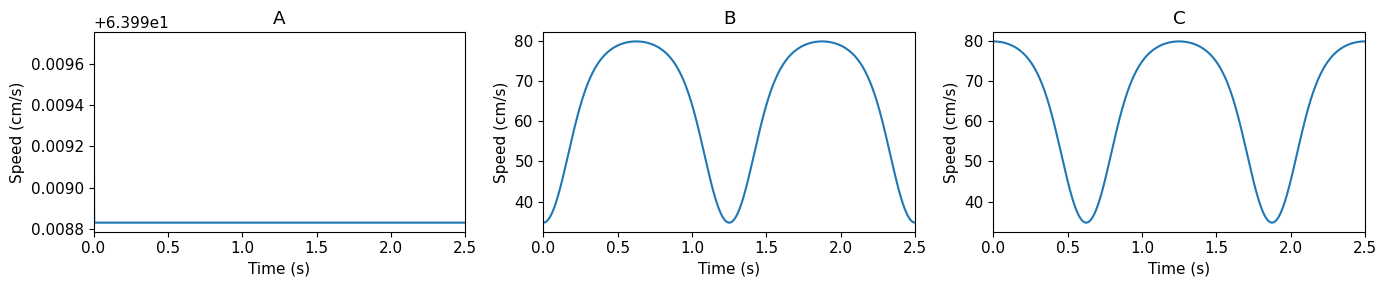

Screening stimuli: 21 | perimeter: 160.0 cm | kinematic speed ratio: 2.294157338705618


In [1]:
from pathlib import Path
import os, sys, json, subprocess, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ellipe
from scipy.integrate import cumulative_trapezoid
import yaml
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'run_pipeline.py').exists())
OUT = ROOT / 'outputs' / 'viviani_batch'
OUT.mkdir(parents=True, exist_ok=True)
OPEN_SIM_PYTHON = ROOT / '.venv-opensim/bin/python'
INFERENCE_PYTHON = ROOT / '.venv-mujoco/bin/python'  # Must contain torch and repository inference dependencies.
CHECKPOINT = ROOT / 'trained_models/experiment_causal_flag-pcr_optimized_linear_extended_5_5_letter_reconstruction_joints/spatiotemporal_4_8-8-32-64_7171_0_9'
PERIMETER_CM = 160.0  # Set 32 for a scaled exploratory control; never label it a replication.
PERIOD_S, FS, CYCLES = 2.5, 240, 3
KINEMATIC_E = 0.9
ECCENTRICITIES = [-0.95, -0.7, -0.4, 0.0, 0.4, 0.7, 0.95]
# np.round(np.arange(-.95, .951, .05), 2) gives the paper's full grid.
RUN_OPENSIM = False  # True regenerates paths and runs the shared biomechanical pipeline.
RUN_CNN = False  # True evaluates all 20 installed CNNs and regenerates readouts.
CIRCLE_RATIO_TOLERANCE = 1.05  # Analysis choice, not a human response category.
IK_MAX_ERROR_CM = 0.1  # Reject mismatched physical paths before drawing model conclusions.
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
CLASSES = ['true circle', 'horizontal ellipse', 'vertical ellipse']

def semiaxes(e, q):
    a = q / (4 * ellipe(float(e)**2))
    b = a * np.sqrt(1 - float(e)**2)
    return (a, b) if e >= 0 else (b, a)

def shape_label(xy, tolerance=CIRCLE_RATIO_TOLERANCE):
    # Extents avoid sampling-density bias from nonuniform speed.
    widths = np.ptp(np.asarray(xy), axis=0)
    if not np.isfinite(widths).all() or widths.min() < 1e-5:
        return 'invalid', np.nan, np.nan
    ratio = widths[0] / widths[1]
    signed_e = np.sign(ratio - 1) * np.sqrt(1 - min(ratio, 1/ratio)**2)
    label = CLASSES[0] if 1/tolerance <= ratio <= tolerance else CLASSES[1 if ratio > 1 else 2]
    return label, ratio, signed_e

def trajectory(e, condition):
    ax, az = semiaxes(e, PERIMETER_CM)
    phi = np.linspace(0, 2*np.pi, 30001)
    x, z = -ax*np.cos(phi), az*np.sin(phi)
    ds = np.sqrt((ax*np.sin(phi))**2 + (az*np.cos(phi))**2)
    if condition == 'A':
        speed = np.ones_like(phi)
    else:
        a, b = semiaxes(KINEMATIC_E, PERIMETER_CM)
        theta = 0 if condition == 'B' else np.pi/2
        u, v = x*np.cos(theta)+z*np.sin(theta), -x*np.sin(theta)+z*np.cos(theta)
        psi = np.arctan2(u/a, v/b)
        speed = (2*np.pi/PERIOD_S)*np.sqrt((a*np.cos(psi))**2+(b*np.sin(psi))**2)
    clock = cumulative_trapezoid(ds/speed, phi, initial=0)
    clock *= PERIOD_S/clock[-1]
    times = np.arange(round(CYCLES*PERIOD_S*FS))/FS
    phase = np.interp(times % PERIOD_S, clock, phi)
    xy = np.column_stack((-ax*np.cos(phase), az*np.sin(phase)))
    return times, xy

trials = []
for e in ECCENTRICITIES:
    for condition in 'ABC':
        t, xy = trajectory(e, condition)
        trials.append(dict(id=f'{condition}_{e:+.2f}'.replace('+','p').replace('-','m').replace('.','_'),
                           condition=condition, e=e, times=t, xy=xy,
                           correct=CLASSES[0] if e==0 else CLASSES[1 if e>0 else 2]))
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, condition in zip(axes, 'ABC'):
    for row in trials:
        if row['condition']==condition:
            ax.plot(*row['xy'].T, label=f"e={row['e']:+.2f}")
    ax.set(title=f'Condition {condition}', xlabel='Horizontal (cm)', ylabel='Vertical (cm)', aspect='equal')
axes[-1].legend(bbox_to_anchor=(1.02,1)); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,3,figsize=(14,3))
for ax, condition in zip(axes,'ABC'):
    row=next(r for r in trials if r['condition']==condition and r['e']==0)
    speed=np.linalg.norm(np.gradient(row['xy'],1/FS,axis=0),axis=1)
    ax.plot(row['times'],speed); ax.set(title=condition,xlabel='Time (s)',ylabel='Speed (cm/s)',xlim=(0,PERIOD_S))
plt.tight_layout(); plt.show()
print('Screening stimuli:',len(trials), '| perimeter:',PERIMETER_CM,'cm | kinematic speed ratio:',1/np.sqrt(1-KINEMATIC_E**2))
settings=dict(perimeter_cm=PERIMETER_CM,period_s=PERIOD_S,fs=FS,cycles=CYCLES,kinematic_e=KINEMATIC_E,eccentricities=list(ECCENTRICITIES))
STIMULUS_SIGNATURE=hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()


## 2. Run those paths through the existing OpenSim pipeline

The same `Pipeline` runner used by `run_pipeline.ipynb` performs inverse kinematics, motion export, muscle-length extraction and spindle-rate generation. The added `opensim_scipy` IK option uses the same OpenSim model, brace, coordinate bounds and marker targets, with bounded warm starts to avoid the poor solutions obtained from the file-based solver in the earlier run.

The requested **160 cm perimeter**, **2.5 s period**, and frontoparallel **X–Z** plane are preserved. The center is approximated as 45 cm forward of the rest shoulder; the paper specified distance from the chest. The repository brace/posture still differs from the paper's nearly extended, palm-down posture. Three cycles are simulated; only the final cycle is classified.

Quality is measured in the fixed rest-shoulder reference used to generate the targets. The earlier diagnostic also mixed this reference with the moving shoulder marker. The pipeline now saves both frames. Rates are synthetic Ia/II signals for 25 muscles, with five afferents of each type per muscle.

The reusable experiment configuration is `experiments/viviani_ellipses.yaml`, with generator `process/generate_paths/ellipses.py`. The notebook invokes the same `Pipeline.run_stage` interface for every biomechanical stage.


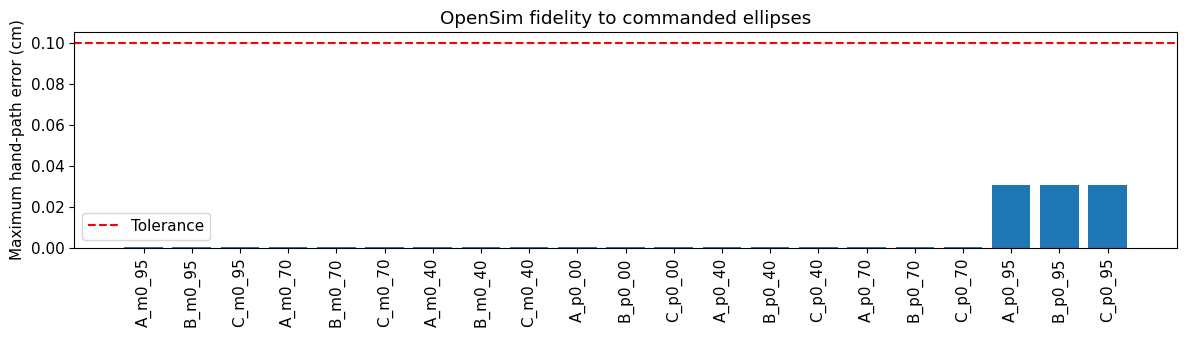

Maximum path error: 0.03074716849463586 cm


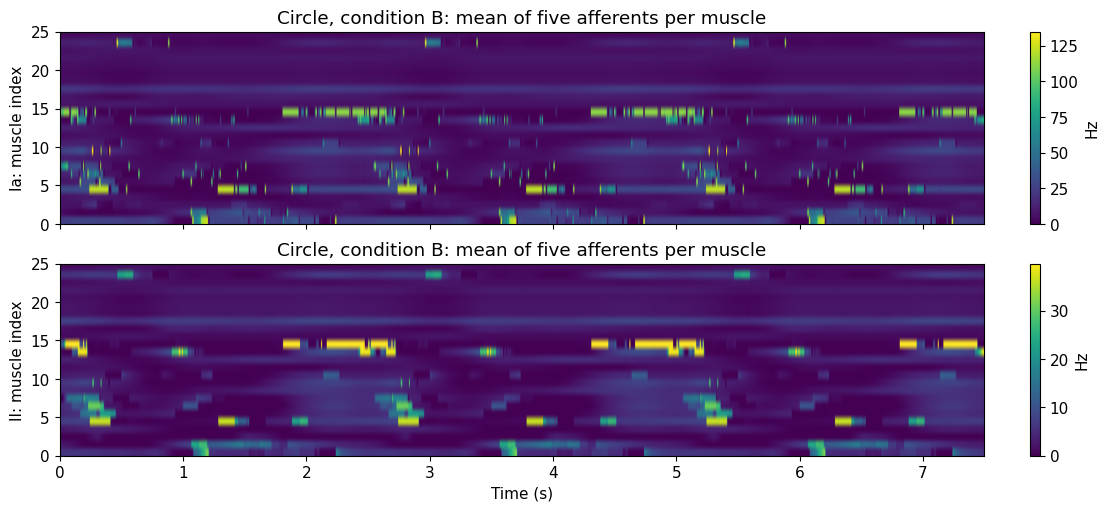

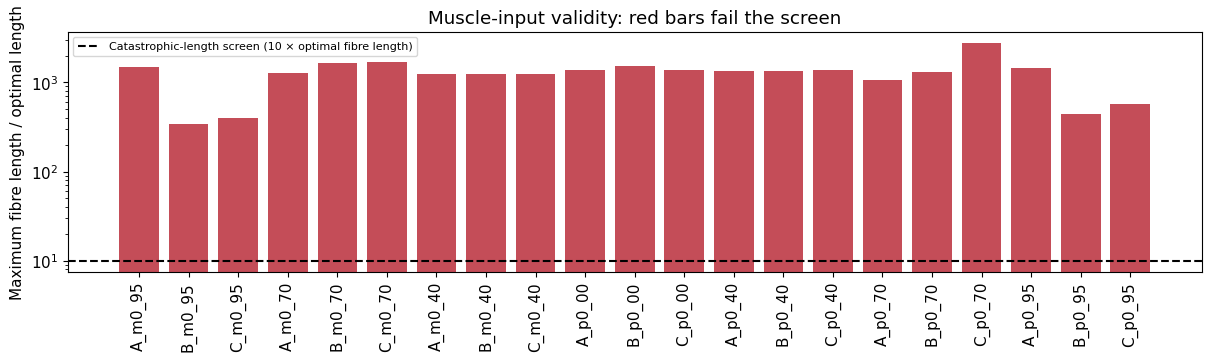

,id,max_ik_error_cm,max_fiber_mm,invalid_fiber_fraction,input_valid
0,A_m0_95,0.000014,111038.414062,0.004467,False
1,B_m0_95,0.000017,25333.941406,0.004267,False
2,C_m0_95,0.000015,29231.201172,0.005267,False
3,A_m0_70,0.000015,94828.289062,0.018333,False
4,B_m0_70,0.000016,123409.085938,0.019533,False
5,C_m0_70,0.000017,124038.726562,0.018000,False
6,A_m0_40,0.000018,92781.031250,0.017333,False
7,B_m0_40,0.000018,92777.960938,0.018533,False
8,C_m0_40,0.000018,92782.203125,0.016333,False
9,A_p0_00,0.000017,101094.890625,0.017267,False


Stimuli passing both path and catastrophic-fibre checks: 0 of 21
STOP INTERPRETATION: CNN plots below are diagnostic computations from contaminated spindle inputs.


In [2]:
config=yaml.safe_load((ROOT/'experiments/center_out.yaml').read_text())
config.update(experiment='viviani_batch',display_simulation=False)
config['ik'].update(backend='opensim_scipy',max_marker_error_cm=IK_MAX_ERROR_CM)
config['proprioception'].update(model_path=str(CHECKPOINT),temporal_padding_mode='zeros')
config['muscle_lengths']['drive_distal_coordinates']=True
config['path']['max_displacement_cm']=PERIMETER_CM
config['path']['generator']='process/generate_paths/ellipses.py'
config['path']['ellipse']=dict(perimeter_cm=PERIMETER_CM,period_s=PERIOD_S,cycles=CYCLES,kinematic_e=KINEMATIC_E,eccentricities=list(ECCENTRICITIES),center_world_cm=[0.,45.,0.])
config_path=OUT/'experiment.yaml'
run_settings=dict(stimuli=settings,ik=config['ik'],muscle_lengths=config['muscle_lengths'],rest=config['path']['rest_pose_degrees'])
STIMULUS_SIGNATURE=hashlib.sha256(json.dumps(run_settings,sort_keys=True).encode()).hexdigest()

def run_command(command,log_name):
    (OUT/'.matplotlib').mkdir(exist_ok=True)
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'),PYTHONPATH=os.pathsep.join([str(ROOT/'process'),str(ROOT)]))
    log=OUT/log_name
    with log.open('w') as stream:
        result=subprocess.run([str(v) for v in command],cwd=ROOT,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode: raise RuntimeError(f'Pipeline failed; see {log}\n'+log.read_text()[-2000:])
    print('Completed:',log_name)

if RUN_OPENSIM:
    for name in ['paths','ik','motions','muscles','spindles','predictions','figures','batch']:(OUT/name).mkdir(exist_ok=True)
    config_path.write_text(yaml.safe_dump(config,sort_keys=False))
    (OUT/'generation.json').write_text(json.dumps(dict(signature=None)))
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:
        launcher=f"from run_pipeline import Pipeline; Pipeline({str(config_path)!r}).run_stage({stage!r})"
        run_command([OPEN_SIM_PYTHON,'-c',launcher],stage+'.log')
    (OUT/'generation.json').write_text(json.dumps(dict(signature=STIMULUS_SIGNATURE,settings=settings),indent=2))

assert (OUT/'generation.json').exists(), 'Run the biomechanical pipeline first (RUN_OPENSIM=True).'
assert json.loads((OUT/'generation.json').read_text())['signature']==STIMULUS_SIGNATURE, 'Settings changed: regenerate the batch.'
manifest=yaml.safe_load((OUT/'manifest.yaml').read_text());entries={r['id']:r for r in manifest['trajectories']}
optimal_lengths=np.asarray(yaml.safe_load((ROOT/'extract_data/configs/train_test_data_spindles_extended.yaml').read_text())['optimal_lengths'])
quality=[]
for row in trials:
    item=entries[row['id']]
    with np.load(OUT/item['muscle_data']) as d:
        desired=np.column_stack((row['xy'][:,0],np.full(len(row['times']),45.),row['xy'][:,1]))
        error=np.linalg.norm(d['wrist_xyz_reference_world']-desired,axis=1)
        fibers=d['fiber_lengths']
        assert np.isfinite(fibers).all() and (fibers>0).all(), 'Invalid fibre lengths'
        max_fiber_mm=float(fibers.max())
        normalized_fibers=fibers/optimal_lengths[None,:]
        bad_fraction=float(np.mean(normalized_fibers>10))
    with np.load(OUT/item['spindle_data']) as d:
        rates=d['firing_rates'];assert rates.shape==(1,10,25,len(row['times'])) and np.isfinite(rates).all()
        quality.append(dict(id=row['id'],max_ik_error_cm=error.max(),mean_ik_error_cm=error.mean(),min_hz=rates.min(),max_hz=rates.max(),max_fiber_mm=max_fiber_mm,max_normalized_fiber=float(normalized_fibers.max()),invalid_fiber_fraction=bad_fraction,input_valid=bad_fraction==0))
quality=pd.DataFrame(quality);quality.to_csv(OUT/'ik_spindle_quality.csv',index=False)
fig,ax=plt.subplots(figsize=(12,3.5));ax.bar(quality.id,quality.max_ik_error_cm)
ax.axhline(IK_MAX_ERROR_CM,c='red',ls='--',label='Tolerance');ax.set(ylabel='Maximum hand-path error (cm)',title='OpenSim fidelity to commanded ellipses');ax.tick_params(axis='x',rotation=90);ax.legend();plt.tight_layout();plt.show()
print('Maximum path error:',quality.max_ik_error_cm.max(),'cm')
row=next(r for r in trials if r['e']==0 and r['condition']=='B')
d=np.load(OUT/entries[row['id']]['spindle_data'])
fig,axes=plt.subplots(2,1,figsize=(11,5),sharex=True,layout='constrained')
for ax,channels,label in zip(axes,[slice(0,5),slice(5,10)],['Ia','II']):
    im=ax.imshow(d['firing_rates'][0,channels].mean(axis=0),origin='lower',aspect='auto',extent=[0,row['times'][-1],0,25])
    ax.set(ylabel=f'{label}: muscle index',title='Circle, condition B: mean of five afferents per muscle');fig.colorbar(im,ax=ax,label='Hz')
axes[-1].set_xlabel('Time (s)');plt.show()

INPUTS_VALID=bool(quality.input_valid.all())
fig,ax=plt.subplots(figsize=(12,3.5),layout='constrained')
ax.bar(quality.id,quality.max_normalized_fiber,color=np.where(quality.input_valid,'#557b9e','#c44d58'))
ax.axhline(10,c='black',ls='--',label='Catastrophic-length screen (10 × optimal fibre length)')
ax.set(yscale='log',ylabel='Maximum fibre length / optimal length',title='Muscle-input validity: red bars fail the screen')
ax.tick_params(axis='x',rotation=90);ax.legend(fontsize=8);plt.show()
display(quality[['id','max_ik_error_cm','max_fiber_mm','invalid_fiber_fraction','input_valid']])
print('Stimuli passing both path and catastrophic-fibre checks:',quality.input_valid.sum(),'of',len(quality))
if not INPUTS_VALID: print('STOP INTERPRETATION: CNN plots below are diagnostic computations from contaminated spindle inputs.')


## 3. Actual CNN outputs, averaged across the 20 pretrained models

The helper calls the repository's existing `load_model`, normalization, and forward-pass functions with the downloaded checkpoints. It retains the original 240 Hz samples and zero temporal padding; no time resizing or training is performed. Each of five coefficient seeds is evaluated with its four training seeds (0, 1, 2, 9).

CNN outputs are seven continuous values per frame, not three shape probabilities. Because its XYZ training convention differs from the OpenSim Handle, we map the four predicted joint angles through the same OpenSim model and classify the resulting physical X–Z path by its extents. Horizontal/vertical extent ratio within [1/1.05, 1.05] is labelled circle. This threshold is prespecified, not fitted to humans. Readout uses every fourth sample of the last cycle.

The plots show individual model reconstructions in light lines and their pointwise mean in color. Out-of-range predicted joint angles are reported, not clipped. Between-model spread is an ensemble description, not human response uncertainty.

**Input validity:** the physical hand-path check passes, but the fibre-length check fails in this run. CNN outputs and averages below are retained as diagnostics and must not be interpreted as perceptual predictions for valid elliptical stimuli.


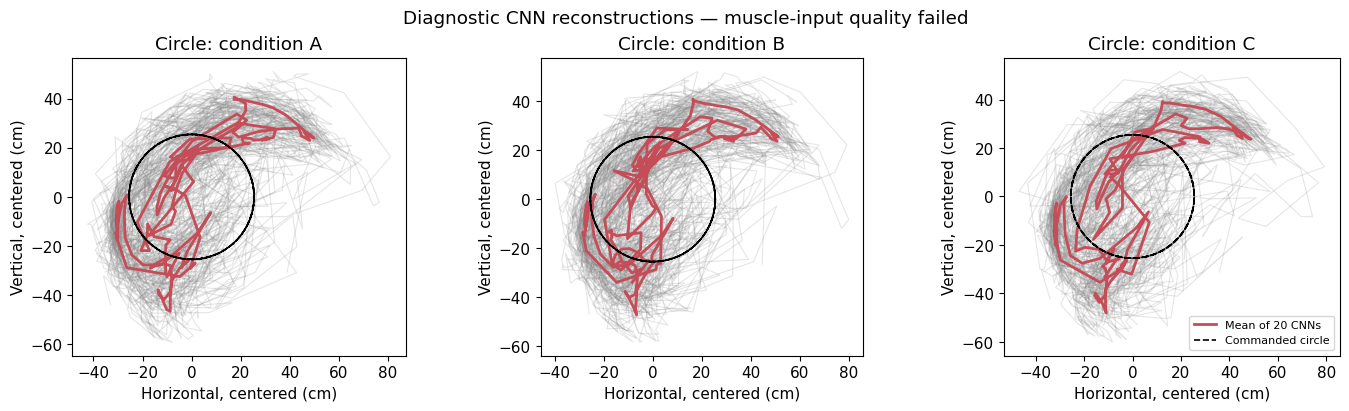

420 predictions across 20 published models and 21 stimuli.
Fraction of readout frames with a predicted joint outside model limits: 0.17692063492063487


,condition,e,mean_predicted_e,sd_predicted_e,mean_ratio,n_models
0,A,-0.95,-0.298309,0.261475,0.927303,20
1,A,-0.70,-0.104518,0.332588,0.969687,20
2,A,-0.40,-0.024765,0.403304,0.990623,20
3,A,0.00,-0.082429,0.387759,0.985520,20
4,A,0.40,0.017308,0.407129,1.003061,20
5,A,0.70,-0.029917,0.395239,0.998710,20
6,A,0.95,0.139282,0.399443,1.037690,20
7,B,-0.95,-0.246028,0.298982,0.946340,20
8,B,-0.70,-0.091725,0.373921,0.981032,20
9,B,-0.40,-0.116588,0.376409,0.969535,20


In [3]:
assert all((CHECKPOINT/f).exists() for f in ['config.yaml','model.ckpt']), 'Install the published weights first.'
assert (quality.max_ik_error_cm<=IK_MAX_ERROR_CM).all(), 'Correct physical-path errors before inference.'
if RUN_CNN:
    run_command([INFERENCE_PYTHON,'process/ellipse_ensemble.py','--output',OUT],'ensemble.log')
    run_command([OPEN_SIM_PYTHON,'process/ellipse_readout.py','--output',OUT,'--tolerance',CIRCLE_RATIO_TOLERANCE],'readout.log')
provenance=json.loads((OUT/'batch/provenance.json').read_text())
readout_metadata=json.loads((OUT/'batch/readout.json').read_text())
assert provenance['source_signature']==STIMULUS_SIGNATURE, 'Inputs changed: rerun CNN inference.'
assert readout_metadata['source_signature']==STIMULUS_SIGNATURE and readout_metadata['tolerance']==CIRCLE_RATIO_TOLERANCE, 'Inputs or threshold changed: regenerate the readout.'
predictions=pd.read_csv(OUT/'batch/shape_predictions.csv')
assert set(predictions.id)==set(r['id'] for r in trials), 'Cached prediction stimuli do not match current settings.'
assert len(predictions)==20*len(trials), 'Incomplete ensemble; run RUN_CNN=True.'
predictions=predictions.drop(columns=['input_valid'],errors='ignore').merge(quality[['id','input_valid']],on='id',validate='many_to_one')
predictions.to_csv(OUT/'batch/shape_predictions.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    row=next(r for r in trials if r['condition']==condition and r['e']==0)
    g=predictions[predictions.id==row['id']];paths=[]
    for item in g.itertuples():
        xy=np.load(OUT/item.physical_prediction)['xyz'][:,[0,2]]
        xy=xy-xy.mean(axis=0);paths.append(xy);ax.plot(*xy.T,c='gray',alpha=.2,lw=.8)
    average=np.mean(paths,axis=0)
    ax.plot(*average.T,c='#c44d58',lw=2,label='Mean of 20 CNNs')
    ax.plot(*row['xy'].T,'k--',lw=1.2,label='Commanded circle')
    ax.set(title=f'Circle: condition {condition}',xlabel='Horizontal, centered (cm)',ylabel='Vertical, centered (cm)',aspect='equal')
axes[-1].legend(fontsize=8);fig.suptitle('Diagnostic CNN reconstructions — muscle-input quality failed' if not INPUTS_VALID else 'CNN reconstructions');plt.show()
summary=predictions.groupby(['condition','e']).agg(mean_predicted_e=('predicted_e','mean'),sd_predicted_e=('predicted_e','std'),mean_ratio=('ratio','mean'),n_models=('predicted_e','size')).reset_index()
summary.to_csv(OUT/'batch/ensemble_summary.csv',index=False)
print(f'{len(predictions)} predictions across 20 published models and {len(trials)} stimuli.')
print('Fraction of readout frames with a predicted joint outside model limits:',predictions.joint_out_of_bounds_fraction.mean())
display(summary)


## 4. CNN output versus the correct answer

Left: confusion counts over all model–stimulus combinations. Middle: mean reconstructed signed eccentricity, with one standard deviation across models. Right: fraction of the 20 models assigning each shape label. These vote fractions are not calibrated human choice probabilities. All three graphs use real checkpoint predictions.


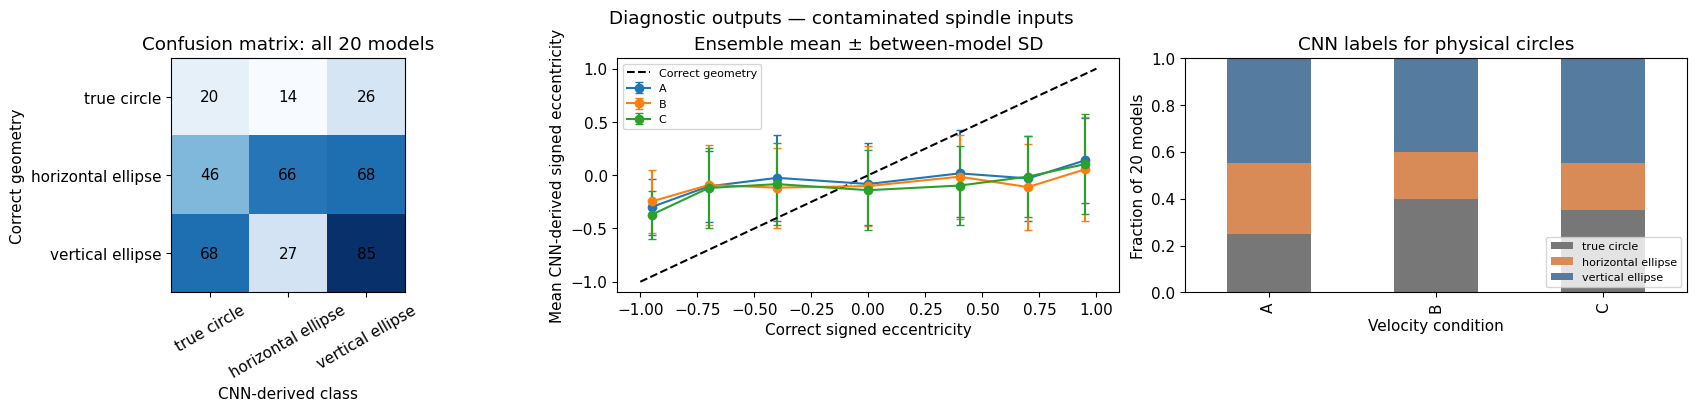

Diagnostic mean per-model classification accuracy: 0.40714285714285714 | between-model SD: 0.14030723453215058


In [4]:
matrix=pd.crosstab(predictions.correct,predictions.predicted).reindex(index=CLASSES,columns=CLASSES,fill_value=0)
fig,axes=plt.subplots(1,3,figsize=(17,4),layout='constrained')
axes[0].imshow(matrix,cmap='Blues');axes[0].set(xticks=range(3),yticks=range(3),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='CNN-derived class',ylabel='Correct geometry',title='Confusion matrix: all 20 models');axes[0].tick_params(axis='x',rotation=30)
for i in range(3):
    for j in range(3):axes[0].text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
for condition,g in summary.groupby('condition'):
    axes[1].errorbar(g.e,g.mean_predicted_e,yerr=g.sd_predicted_e,fmt='o-',capsize=3,label=condition)
axes[1].plot([-1,1],[-1,1],'k--',label='Correct geometry');axes[1].set(xlabel='Correct signed eccentricity',ylabel='Mean CNN-derived signed eccentricity',title='Ensemble mean ± between-model SD');axes[1].legend(fontsize=8)
circle=predictions[predictions.e==0]
votes=pd.crosstab(circle.condition,circle.predicted,normalize='index').reindex(index=list('ABC'),columns=CLASSES,fill_value=0)
votes.plot.bar(stacked=True,ax=axes[2],color=['#777777','#d98b57','#557b9e']);axes[2].set(ylabel='Fraction of 20 models',xlabel='Velocity condition',title='CNN labels for physical circles',ylim=(0,1));axes[2].legend(fontsize=8,loc='lower right');fig.suptitle('Diagnostic outputs — contaminated spindle inputs' if not INPUTS_VALID else 'Model versus correct geometry');plt.show()
accuracy=predictions.assign(correct_response=predictions.correct==predictions.predicted).groupby(['coefficient_seed','training_seed']).correct_response.mean()
print('Diagnostic mean per-model classification accuracy:',accuracy.mean(),'| between-model SD:',accuracy.std())


## 5. CNN versus human data: circularity bias and sensitivity

Humans chose flat/tall; they did not have a circle response. The comparable endpoint is the physical eccentricity at subjective circularity (PSE). Table 1 gives mean human PSEs for 20 people: A −.091, B −.267, C .026. We do not treat the table's inversion-level dispersion as a participant-level standard error. Human JND values (.095, .148, .114) come from the normalized psychometric analysis (Figure 3).

For each pretrained CNN, we locate the unique zero crossing of reconstructed signed eccentricity versus commanded eccentricity, linearly interpolating the screening grid. No crossing or multiple crossings produce a missing PSE, which is reported. We average PSEs **after** finding them separately per model; this differs from finding a crossing of the ensemble-mean trajectory. The plot displays individual model PSEs, their mean and SD, and the human means. Differential shifts B−A and C−A address the velocity-induced illusion.

The deterministic ensemble does not supply a psychometric JND; the human sensitivity panel is therefore a reference only. Any predicted joint-limit violations, posture differences, and coarse PSE interpolation limit interpretation. Agreement does not establish a shared biological mechanism.

**This run does not support an alignment conclusion:** the model markers are based on spindle inputs contaminated by wrapping artifacts. They are shown alongside the human references to diagnose the pipeline, not to claim agreement or disagreement.


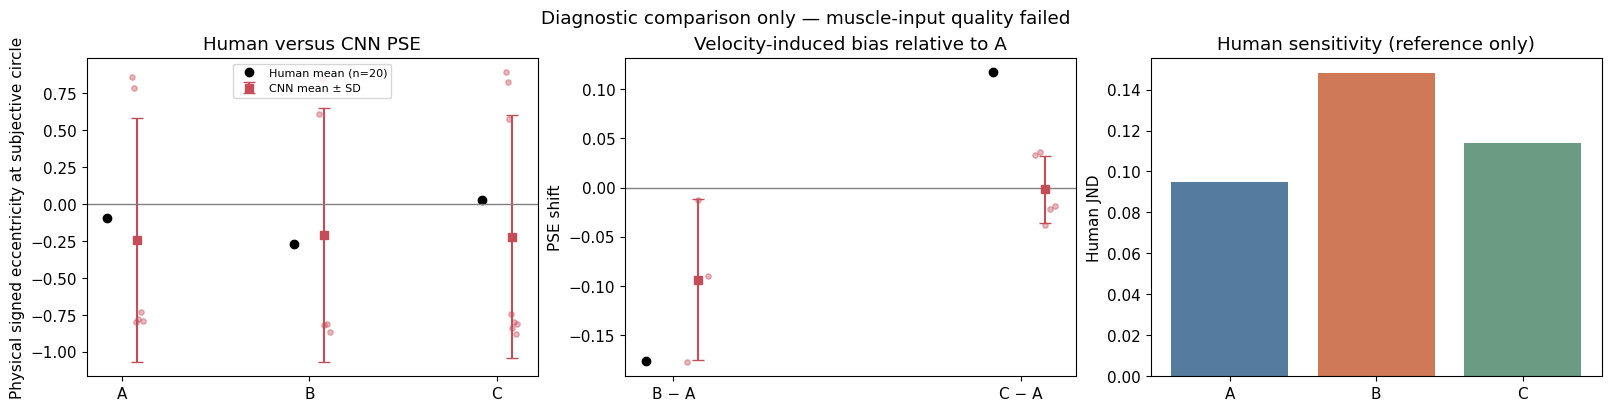

,condition,pse,n,jnd,model_mean,model_sd,valid_models,model_minus_human,input_quality_passed
0,A,-0.091,20,0.095,-0.241837,0.825954,6,-0.150837,False
1,B,-0.267,20,0.148,-0.207872,0.859366,5,0.059128,False
2,C,0.026,20,0.114,-0.222633,0.822741,8,-0.248633,False


,contrast,human_shift,cnn_mean_shift,valid_model_pairs
0,B-A,-0.176,-0.093519,3
1,C-A,0.117,-0.001921,5


Missing / nonunique PSE crossings: 41 of 60
Next scientific check: refine the grid around each PSE and repeat with kinematic eccentricity .95 and a paper-matched arm posture.
No scientific alignment conclusion: correct the wrapping artifacts and rerun the same batch first.


In [5]:
human=pd.DataFrame(dict(condition=list('ABC'),pse=[-.091,-.267,.026],n=[20]*3,jnd=[.095,.148,.114]))
human.to_csv(OUT/'human_reference.csv',index=False)
def zero_crossing(x,y):
    x,y=np.asarray(x),np.asarray(y)
    if not np.isfinite(y).all():return np.nan
    order=np.argsort(x);x,y=x[order],y[order];roots=list(x[np.abs(y)<1e-10])
    for i in range(len(x)-1):
        if y[i]*y[i+1]<0:roots.append(x[i]-y[i]*(x[i+1]-x[i])/(y[i+1]-y[i]))
    return roots[0] if len(roots)==1 else np.nan
pse_rows=[]
for (coef,train,condition),g in predictions.groupby(['coefficient_seed','training_seed','condition']):
    pse_rows.append(dict(coefficient_seed=coef,training_seed=train,condition=condition,model_pse=zero_crossing(g.e,g.predicted_e)))
model_pse=pd.DataFrame(pse_rows);model_pse.to_csv(OUT/'batch/model_pses.csv',index=False)
comparison=human.merge(model_pse.groupby('condition').model_pse.agg(model_mean='mean',model_sd='std',valid_models='count').reset_index(),on='condition')
comparison['model_minus_human']=comparison.model_mean-comparison.pse
comparison['input_quality_passed']=INPUTS_VALID
comparison.to_csv(OUT/'human_model_comparison.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained');x=np.arange(3)
axes[0].plot(x-.08,human.pse,'ko',label='Human mean (n=20)')
for i,condition in enumerate('ABC'):
    values=model_pse[model_pse.condition==condition].model_pse.dropna().to_numpy()
    axes[0].scatter(i+.08+np.linspace(-.03,.03,len(values)),values,c='#c44d58',alpha=.4,s=15)
axes[0].errorbar(x+.08,comparison.model_mean,yerr=comparison.model_sd,fmt='s',capsize=4,c='#c44d58',label='CNN mean ± SD')
axes[0].axhline(0,c='gray',lw=1);axes[0].set(xticks=x,xticklabels=list('ABC'),ylabel='Physical signed eccentricity at subjective circle',title='Human versus CNN PSE');axes[0].legend(fontsize=8)
wide=model_pse.pivot(index=['coefficient_seed','training_seed'],columns='condition',values='model_pse')
shift_rows=[]
for i,condition in enumerate('BC'):
    values=(wide[condition]-wide.A).dropna()
    h=human.set_index('condition').pse;human_shift=h[condition]-h.A
    axes[1].scatter(i+.07+np.linspace(-.03,.03,len(values)),values,c='#c44d58',alpha=.4,s=15)
    axes[1].plot(i-.08,human_shift,'ko')
    if len(values):axes[1].errorbar(i+.07,values.mean(),yerr=values.std(),fmt='s',c='#c44d58',capsize=4)
    shift_rows.append(dict(contrast=condition+'-A',human_shift=human_shift,cnn_mean_shift=values.mean(),valid_model_pairs=len(values)))
axes[1].axhline(0,c='gray',lw=1);axes[1].set(xticks=[0,1],xticklabels=['B − A','C − A'],ylabel='PSE shift',title='Velocity-induced bias relative to A')
axes[2].bar(x,human.jnd,color=['#557b9e','#cf7957','#6b9b82']);axes[2].set(xticks=x,xticklabels=list('ABC'),ylabel='Human JND',title='Human sensitivity (reference only)')
fig.suptitle('Diagnostic comparison only — muscle-input quality failed' if not INPUTS_VALID else 'CNN versus human references');plt.show();display(comparison);display(pd.DataFrame(shift_rows))
pd.DataFrame(shift_rows).to_csv(OUT/'batch/pse_shifts.csv',index=False)
print('Missing / nonunique PSE crossings:',model_pse.model_pse.isna().sum(),'of',len(model_pse))
print('Next scientific check: refine the grid around each PSE and repeat with kinematic eccentricity .95 and a paper-matched arm posture.')

if not INPUTS_VALID: print('No scientific alignment conclusion: correct the wrapping artifacts and rerun the same batch first.')


**Reproducibility and averaging.** All outputs live in `outputs/viviani_batch/`. `batch/provenance.json` records checkpoint checksums and runtime; `batch/inventory.csv` lists every model–stimulus prediction. The helper modules implement bounded OpenSim IK, existing CNN inference, and physical-coordinate readout. No model is trained or fitted to human responses. Deterministic repeat cycles are warm-up, not independent trials. The 20 models share architecture and training data, so their SD is not a population confidence interval.

The existing `run_pipeline.ipynb` remains unchanged by this work. To recompute this notebook, set `RUN_OPENSIM=True` and `RUN_CNN=True` and run cells in order. The installed weights are ignored by Git but remain available locally. Preserve their archive provenance when moving the project.
